In [1]:
import pandas as pd
import numpy as np
import sys
import os
from tqdm import tqdm
import sys

In [2]:
sys.path.append('../src/')

In [3]:
from visualization import *

# Data import

In [4]:
all_metrics = pd.read_csv('../data/all_metrics.csv')

In [5]:
## Equality and Mutuality metrics (See Lee et al. 2022)
# equality (how evenly a writer and GAI distributed turns (e.g. the degree of deviation from even division of work))

all_metrics["equality"] = 1 - abs((all_metrics["nb_sentences_full_user"]-all_metrics["nb_sentences_full_GPT"])/(all_metrics["nb_sentences_full_user"]+all_metrics["nb_sentences_full_GPT"]))



# mutuality (level of interaction a writer has with GAI)
all_metrics["mutuality"] = all_metrics["nb_sentences_GPT_user"]/(all_metrics["nb_sentences_full_user"]+all_metrics["nb_sentences_GPT_user"])

# Compute Authorship Calibration

In [6]:
all_metrics['calibration'] = all_metrics['written_by_human_decla'].astype(int) - all_metrics['written_by_human'].astype(int)
all_metrics['calibration_score'] = all_metrics['calibration'] / 100

all_metrics['abs_calibration_score'] = all_metrics['calibration_score'].abs()

# Explore metrics across GenAI interaction dynamics

5 metrics are explored: 
* **Product-based authorship**: varies between $0\%$ (entirely AI generated content) and $100\%$ (entirely human written content).
* **Raw authorship calibration**: varies between $-1$ (under-calibration) and $1$ (over-calibration). A score of $0$ reflects a perfect calibration.
* **Absolute authorship calibration**: varies between $0$ (perfect calibration) and $1$ (maximal miscalibration). 
* **Equality**: varies between $0$ (no turn change) and $1$ (symmetrical division of turns).
* **Mutuality**: varies between $0$ (no interaction with the AI) and $1$ (continuous interaction with the AI).

In [7]:
from itertools import combinations
from statsmodels.stats.multitest import multipletests
from scipy.stats import normaltest
import scipy.stats as stats
from scipy.stats import mannwhitneyu, kstest
from scipy.stats import probplot
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2
from statsmodels.stats.multicomp import pairwise_tukeyhsd

## Product-based authorship

### LMM model

            Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: written_by_human
No. Observations: 763     Method:             REML            
No. Groups:       53      Scale:              90.0211         
Min. group size:  1       Log-Likelihood:     -2843.3519      
Max. group size:  65      Converged:          Yes             
Mean group size:  14.4                                        
---------------------------------------------------------------
                Coef.   Std.Err.    z     P>|z|  [0.025  0.975]
---------------------------------------------------------------
C(cluster)[0]   69.781     1.541  45.292  0.000  66.762  72.801
C(cluster)[1]   82.311     1.328  61.967  0.000  79.707  84.914
C(cluster)[2]   59.935     1.797  33.358  0.000  56.413  63.456
C(cluster)[3]   74.484     1.589  46.877  0.000  71.370  77.599
Group Var       65.394     1.712                               



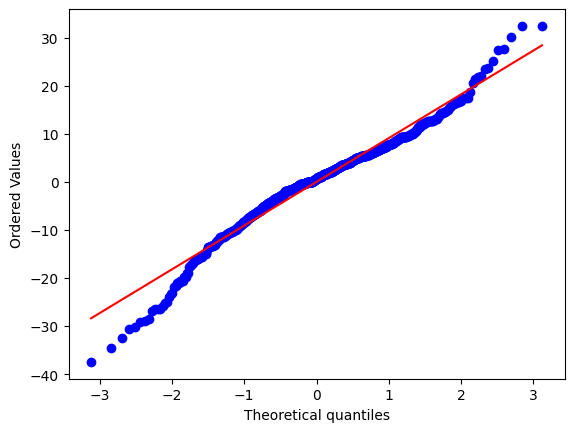

In [8]:
# Ensure cluster is treated as categorical (e.g., C(cluster_id))
all_metrics["cluster"] = all_metrics["cluster"].astype("category")

# 1. Fit the Linear Mixed Model
# 'abs_calibration_score ~ C(cluster_id)' automatically creates dummy variables
lmm_cluster_authorship = smf.mixedlm(
    "written_by_human ~ C(cluster) - 1",
    data=all_metrics,
    groups=all_metrics["worker_id"],
)
lmm_cluster_authorship_result = lmm_cluster_authorship.fit()
print(lmm_cluster_authorship_result.summary())

residuals = lmm_cluster_authorship_result.resid
probplot(residuals, dist="norm", plot=plt)
plt.title("")
plt.show()

In [9]:
# Extract model-based means and 95% confidence intervals for each cluster
fixed_effects = lmm_cluster_authorship_result.fe_params
cov_matrix = lmm_cluster_authorship_result.cov_params().loc[fixed_effects.index, fixed_effects.index]

clusters = sorted(all_metrics["cluster"].unique())
means_authorship = []
ci_lower_authorship = []
ci_upper_authorship = []

for cluster in clusters:
    param_name = f"C(cluster)[{cluster}]"
    mean = float(fixed_effects[param_name])
    standard_error = float(np.sqrt(cov_matrix.loc[param_name, param_name]))
    means_authorship.append(mean)
    ci_lower_authorship.append(mean - 1.96 * standard_error)
    ci_upper_authorship.append(mean + 1.96 * standard_error)

df_emmeans_authorship = pd.DataFrame(
    {
        "cluster_id": clusters,
        "mean": means_authorship,
        "ci_lower": ci_lower_authorship,
        "ci_upper": ci_upper_authorship,
    }
)

df_emmeans_authorship

,cluster_id,mean,ci_lower,ci_upper
0,0,69.781340,66.761576,72.801105
1,1,82.310617,79.707174,84.914060
2,2,59.934667,56.413071,63.456263
3,3,74.484305,71.369974,77.598635


### Wald $\chi^2$ test

In [10]:
hypothesis = hypothesis = (
    "C(cluster)[0] = C(cluster)[1], "
    "C(cluster)[0] = C(cluster)[2], " 
    "C(cluster)[0] = C(cluster)[3] "
)


wald_test = lmm_cluster_authorship_result.wald_test(hypothesis)
print(f"Chi2: {wald_test.statistic}")
print(f"p-value: {wald_test.pvalue}")

Chi2: [[252.6286069]]
p-value: 1.7671986056768202e-54


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


### T-test for pairwise comparison (with Bonferroni correction)

In [11]:
# 1. Get the fixed-effects parameter names
fe_params = list(lmm_cluster_authorship_result.fe_params.index)
n_params = len(fe_params)

# 2. Iterate over all pairs of clusters
pairwise_results = []

for p1, p2 in combinations(fe_params, 2):
    r_matrix = np.zeros(n_params)
    r_matrix[fe_params.index(p1)] = 1
    r_matrix[fe_params.index(p2)] = -1
    r_matrix = r_matrix.reshape(1, -1)  # Reshape to 2D for the t_test function

    # Run the t-test with the NumPy matrix
    test = lmm_cluster_authorship_result.t_test(r_matrix)

    # Safely extract the values
    diff = float(np.asarray(test.effect).squeeze())
    sd = float(np.asarray(test.sd).squeeze())
    z_stat = float(np.asarray(test.tvalue).squeeze())
    p_val = float(np.asarray(test.pvalue).squeeze())

    # Clean up names for readability in the table
    label1 = p1.replace("C(cluster)[", "").replace("]", "").replace("[", "")
    label2 = p2.replace("C(cluster)[", "").replace("]", "").replace("[", "")

    pairwise_results.append(
        {
            "Comparison": f"{label1} vs {label2}",
            "Diff (p1 - p2)": diff,
            "Std_Err": sd,
            "z": z_stat,
            "p_value_raw": p_val,
        }
    )

df_posthoc_authorship = pd.DataFrame(pairwise_results)

# 3. Bonferroni correction for multiple comparisons
reject, p_adjusted, _, _ = multipletests(
    df_posthoc_authorship["p_value_raw"], alpha=0.05, method="bonferroni"
)

# 4. Add the adjusted columns to the DataFrame
df_posthoc_authorship["p_value_bonferroni"] = p_adjusted
df_posthoc_authorship["Significant (alpha=0.05)"] = reject

# Display the results
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
print(df_posthoc_authorship)

  Comparison  Diff (p1 - p2)   Std_Err          z   p_value_raw  p_value_bonferroni  Significant (alpha=0.05)
0     0 vs 1      -12.529277  1.139713 -10.993361  4.113184e-28        2.467910e-27                      True
1     0 vs 2        9.846674  1.411480   6.976132  3.034178e-12        1.820507e-11                      True
2     0 vs 3       -4.702964  1.331061  -3.533245  4.104912e-04        2.462947e-03                      True
3     1 vs 2       22.375950  1.476924  15.150369  7.534295e-52        4.520577e-51                      True
4     1 vs 3        7.826312  1.201495   6.513812  7.326705e-11        4.396023e-10                      True
5     2 vs 3      -14.549638  1.562059  -9.314400  1.226443e-20        7.358659e-20                      True


/Users/treuilli/Documents/GitHub/GenAI_Interaction_Dynamics_Authorship/notebooks/../src/visualization.py:115: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


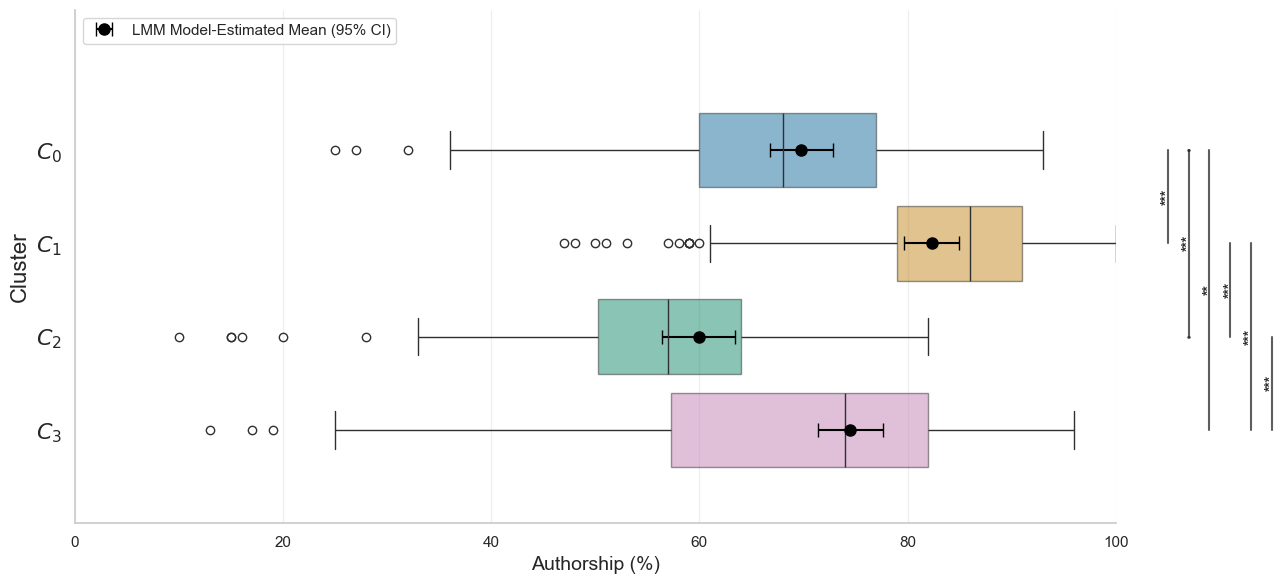

In [12]:
plot_lmm_coeffs(all_metrics, df_emmeans_authorship, clusters[::-1], df_posthoc_authorship, metric='written_by_human', n_clusters_optimal=4, x_axis_label='Authorship (%)', name_fig='authorship', save_fig=True)

## Raw calibration scores

### LMM model

             Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: calibration_score
No. Observations: 763     Method:             REML             
No. Groups:       53      Scale:              0.0105           
Min. group size:  1       Log-Likelihood:     590.5155         
Max. group size:  65      Converged:          Yes              
Mean group size:  14.4                                         
----------------------------------------------------------------
                 Coef.   Std.Err.    z     P>|z|  [0.025  0.975]
----------------------------------------------------------------
C(cluster)[0]     0.000     0.018   0.025  0.980  -0.034   0.035
C(cluster)[1]    -0.029     0.015  -1.857  0.063  -0.059   0.002
C(cluster)[2]     0.065     0.020   3.228  0.001   0.026   0.104
C(cluster)[3]    -0.016     0.018  -0.885  0.376  -0.051   0.019
Group Var         0.009     0.023                               



/opt/anaconda3/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


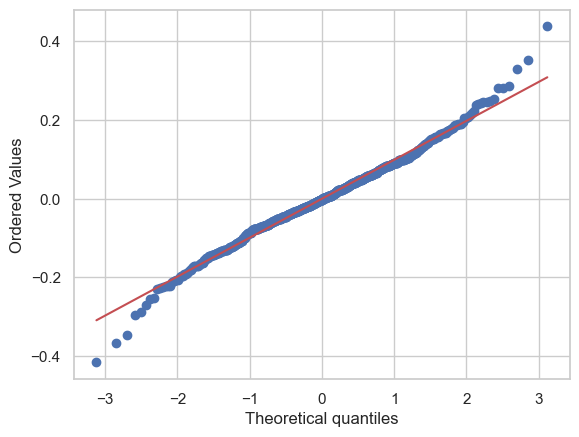

In [13]:
# Ensure cluster is treated as categorical (e.g., C(cluster_id))
all_metrics["cluster"] = all_metrics["cluster"].astype("category")

# 1. Fit the Linear Mixed Model
# 'abs_calibration_score ~ C(cluster_id)' automatically creates dummy variables
lmm_cluster_raw = smf.mixedlm(
    "calibration_score ~ C(cluster) - 1",
    data=all_metrics,
    groups=all_metrics["worker_id"],
)
lmm_cluster_raw_result = lmm_cluster_raw.fit()
print(lmm_cluster_raw_result.summary())

residuals = lmm_cluster_raw_result.resid
probplot(residuals, dist="norm", plot=plt)
plt.title("")
plt.show()

In [14]:
# Extract model-based means and 95% confidence intervals for each cluster
fixed_effects = lmm_cluster_raw_result.fe_params
cov_matrix = lmm_cluster_raw_result.cov_params().loc[fixed_effects.index, fixed_effects.index]

clusters = sorted(all_metrics["cluster"].unique())
means_raw = []
ci_lower_raw = []
ci_upper_raw = []

for cluster in clusters:
    param_name = f"C(cluster)[{cluster}]"
    mean = float(fixed_effects[param_name])
    standard_error = float(np.sqrt(cov_matrix.loc[param_name, param_name]))
    means_raw.append(mean)
    ci_lower_raw.append(mean - 1.96 * standard_error)
    ci_upper_raw.append(mean + 1.96 * standard_error)

df_emmeans_raw = pd.DataFrame(
    {
        "cluster_id": clusters,
        "mean": means_raw,
        "ci_lower": ci_lower_raw,
        "ci_upper": ci_upper_raw,
    }
)

df_emmeans_raw

,cluster_id,mean,ci_lower,ci_upper
0,0,0.000437,-0.034027,0.034902
1,1,-0.028774,-0.059138,0.001589
2,2,0.065015,0.025535,0.104495
3,3,-0.015937,-0.051243,0.019369


### Wald $\chi^2$ test

In [15]:
hypothesis = hypothesis = (
    "C(cluster)[0] = C(cluster)[1], "
    "C(cluster)[0] = C(cluster)[2], " 
    "C(cluster)[0] = C(cluster)[3]"
)


wald_test = lmm_cluster_raw_result.wald_test(hypothesis)
print(f"Chi2: {wald_test.statistic}")
print(f"p-value: {wald_test.pvalue}")

Chi2: [[35.78544018]]
p-value: 8.312805421825928e-08


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


### T-test for pairwise comparison (with Bonferroni correction)

In [16]:
# 1. Get the fixed-effects parameter names
fe_params = list(lmm_cluster_raw_result.fe_params.index)
n_params = len(fe_params)

# 2. Iterate over all pairs of clusters
pairwise_results = []

for p1, p2 in combinations(fe_params, 2):
    r_matrix = np.zeros(n_params)
    r_matrix[fe_params.index(p1)] = 1
    r_matrix[fe_params.index(p2)] = -1
    r_matrix = r_matrix.reshape(1, -1)  # Reshape to 2D for the t_test function

    # Run the t-test with the NumPy matrix
    test = lmm_cluster_raw_result.t_test(r_matrix)

    # Safely extract the values
    diff = float(np.asarray(test.effect).squeeze())
    sd = float(np.asarray(test.sd).squeeze())
    z_stat = float(np.asarray(test.tvalue).squeeze())
    p_val = float(np.asarray(test.pvalue).squeeze())

    # Clean up names for readability in the table
    label1 = p1.replace("C(cluster)[", "").replace("]", "").replace("[", "")
    label2 = p2.replace("C(cluster)[", "").replace("]", "").replace("[", "")

    pairwise_results.append(
        {
            "Comparison": f"{label1} vs {label2}",
            "Diff (p1 - p2)": diff,
            "Std_Err": sd,
            "z": z_stat,
            "p_value_raw": p_val,
        }
    )

df_posthoc_raw = pd.DataFrame(pairwise_results)

# 3. Bonferroni correction for multiple comparisons
reject, p_adjusted, _, _ = multipletests(
    df_posthoc_raw["p_value_raw"], alpha=0.05, method="bonferroni"
)

# 4. Add the adjusted columns to the DataFrame
df_posthoc_raw["p_value_bonferroni"] = p_adjusted
df_posthoc_raw["Significant (alpha=0.05)"] = reject

# Display the results
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
print(df_posthoc_raw)

  Comparison  Diff (p1 - p2)   Std_Err         z   p_value_raw  p_value_bonferroni  Significant (alpha=0.05)
0     0 vs 1        0.029212  0.012358  2.363725  1.809225e-02        1.085535e-01                     False
1     0 vs 2       -0.064578  0.015217 -4.243709  2.198550e-05        1.319130e-04                      True
2     0 vs 3        0.016374  0.014384  1.138392  2.549569e-01        1.000000e+00                     False
3     1 vs 2       -0.093789  0.015904 -5.897221  3.696746e-09        2.218048e-08                      True
4     1 vs 3       -0.012837  0.012926 -0.993115  3.206540e-01        1.000000e+00                     False
5     2 vs 3        0.080952  0.016873  4.797618  1.605632e-06        9.633794e-06                      True


/Users/treuilli/Documents/GitHub/GenAI_Interaction_Dynamics_Authorship/notebooks/../src/visualization.py:115: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


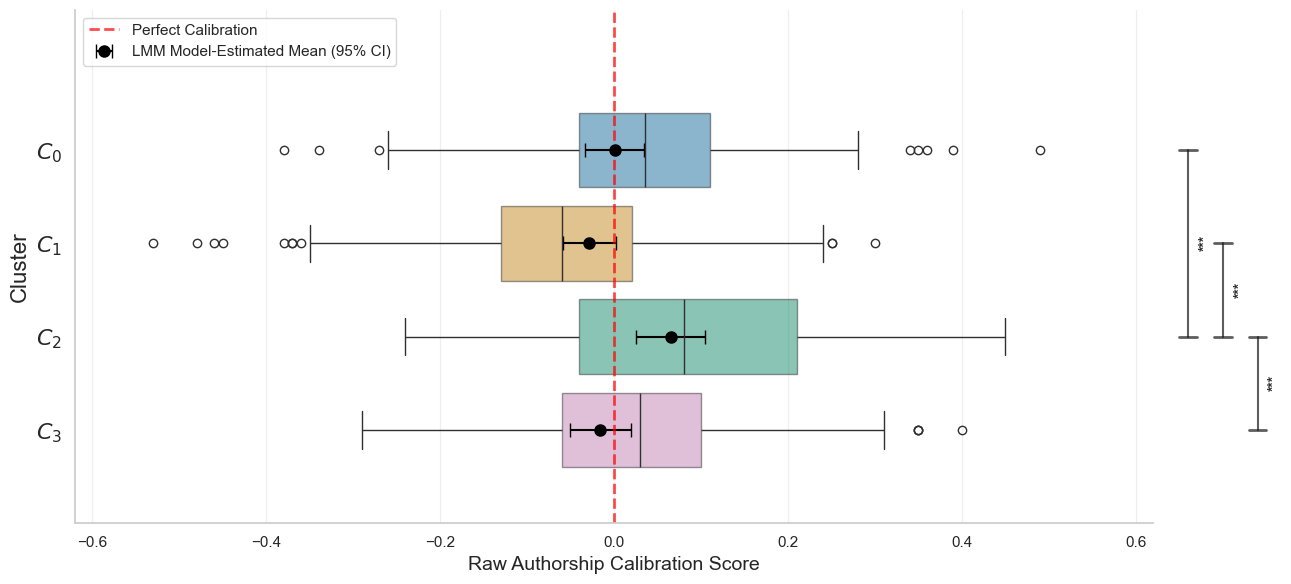

In [17]:
plot_lmm_coeffs(all_metrics, df_emmeans_raw, clusters[::-1], df_posthoc_raw, metric='calibration_score', n_clusters_optimal=4, x_axis_label='Raw Authorship Calibration Score', name_fig='raw_calibration', save_fig=True)

## Absolute calibration scores

### LMM model

               Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: abs_calibration_score
No. Observations: 763     Method:             REML                 
No. Groups:       53      Scale:              0.0063               
Min. group size:  1       Log-Likelihood:     799.0573             
Max. group size:  65      Converged:          Yes                  
Mean group size:  14.4                                             
---------------------------------------------------------------------
                  Coef.   Std.Err.     z      P>|z|   [0.025   0.975]
---------------------------------------------------------------------
C(cluster)[0]     0.117      0.011   10.480   0.000    0.095    0.138
C(cluster)[1]     0.101      0.009   10.997   0.000    0.083    0.119
C(cluster)[2]     0.157      0.013   11.742   0.000    0.131    0.183
C(cluster)[3]     0.107      0.012    9.248   0.000    0.084    0.130
Group Var         0.003      0.010               

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


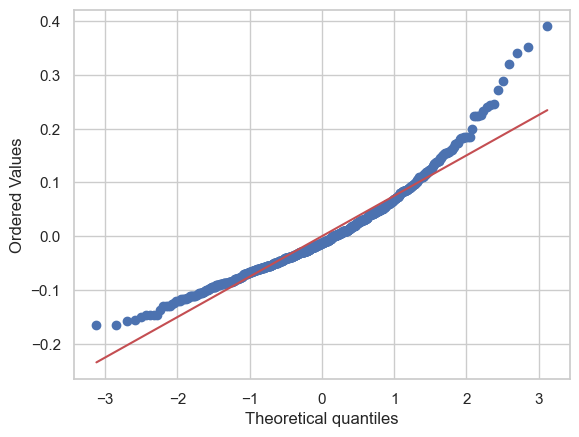

In [18]:
# Ensure cluster is treated as categorical (e.g., C(cluster_id))
all_metrics["cluster"] = all_metrics["cluster"].astype("category")

# 1. Fit the Linear Mixed Model
# 'abs_calibration_score ~ C(cluster_id)' automatically creates dummy variables
lmm_cluster_abs = smf.mixedlm(
    "abs_calibration_score ~ C(cluster) - 1",
    data=all_metrics,
    groups=all_metrics["worker_id"],
)
lmm_cluster_abs_result = lmm_cluster_abs.fit()
print(lmm_cluster_abs_result.summary())

residuals = lmm_cluster_abs_result.resid
probplot(residuals, dist="norm", plot=plt)
plt.title("")
plt.show()

In [19]:
# Extract model-based means and 95% confidence intervals for each cluster
fixed_effects_abs = lmm_cluster_abs_result.fe_params
cov_matrix_abs = lmm_cluster_abs_result.cov_params().loc[fixed_effects.index, fixed_effects.index]

clusters = sorted(all_metrics["cluster"].unique())
means_abs = []
ci_lower_abs = []
ci_upper_abs = []

for cluster in clusters:
    param_name = f"C(cluster)[{cluster}]"
    mean = float(fixed_effects_abs[param_name])
    standard_error = float(np.sqrt(cov_matrix_abs.loc[param_name, param_name]))
    means_abs.append(mean)
    ci_lower_abs.append(mean - 1.96 * standard_error)
    ci_upper_abs.append(mean + 1.96 * standard_error)

df_emmeans_abs = pd.DataFrame(
    {
        "cluster_id": clusters,
        "mean": means_abs,
        "ci_lower": ci_lower_abs,
        "ci_upper": ci_upper_abs,
    }
)

df_emmeans_abs

,cluster_id,mean,ci_lower,ci_upper
0,0,0.116547,0.094751,0.138343
1,1,0.100802,0.082837,0.118768
2,2,0.157052,0.130836,0.183268
3,3,0.106918,0.084257,0.129579


### Wald $\chi^2$ test

In [20]:
hypothesis = hypothesis = (
    "C(cluster)[0] = C(cluster)[1], "
    "C(cluster)[0] = C(cluster)[2], " 
    "C(cluster)[0] = C(cluster)[3] "
)


wald_test = lmm_cluster_abs_result.wald_test(hypothesis)
print(f"Chi2: {wald_test.statistic}")
print(f"p-value: {wald_test.pvalue}")

Chi2: [[22.5223031]]
p-value: 5.078407776272481e-05


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


### T-test for pairwise comparison (with Bonferroni correction)

In [21]:
# 1. Get the fixed-effects parameter names
fe_params_abs = list(lmm_cluster_abs_result.fe_params.index)
n_params = len(fe_params_abs)

# 2. Iterate over all pairs of clusters
pairwise_results = []

for p1, p2 in combinations(fe_params_abs, 2):
    r_matrix = np.zeros(n_params)
    r_matrix[fe_params_abs.index(p1)] = 1
    r_matrix[fe_params_abs.index(p2)] = -1
    r_matrix = r_matrix.reshape(1, -1)  # Reshape to 2D for the t_test function

    # Run the t-test with the NumPy matrix
    test = lmm_cluster_abs_result.t_test(r_matrix)

    # Safely extract the values
    diff = float(np.asarray(test.effect).squeeze())
    sd = float(np.asarray(test.sd).squeeze())
    z_stat = float(np.asarray(test.tvalue).squeeze())
    p_val = float(np.asarray(test.pvalue).squeeze())

    # Clean up names for readability in the table
    label1 = p1.replace("C(cluster)[", "").replace("]", "").replace("[", "")
    label2 = p2.replace("C(cluster)[", "").replace("]", "").replace("[", "")

    pairwise_results.append(
        {
            "Comparison": f"{label1} vs {label2}",
            "Diff (p1 - p2)": diff,
            "Std_Err": sd,
            "z": z_stat,
            "p_value_raw": p_val,
        }
    )

df_posthoc_abs = pd.DataFrame(pairwise_results)

# 3. Bonferroni correction for multiple comparisons
reject, p_adjusted, _, _ = multipletests(
    df_posthoc_abs["p_value_raw"], alpha=0.05, method="bonferroni"
)

# 4. Add the adjusted columns to the DataFrame
df_posthoc_abs["p_value_bonferroni"] = p_adjusted
df_posthoc_abs["Significant (alpha=0.05)"] = reject

# Display the results
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
print(df_posthoc_abs)

  Comparison  Diff (p1 - p2)   Std_Err         z  p_value_raw  p_value_bonferroni  Significant (alpha=0.05)
0     0 vs 1        0.015745  0.009362  1.681776     0.092612            0.555674                     False
1     0 vs 2       -0.040505  0.011719 -3.456404     0.000547            0.003285                      True
2     0 vs 3        0.009629  0.011055  0.870983     0.383764            1.000000                     False
3     1 vs 2       -0.056249  0.012070 -4.660252     0.000003            0.000019                      True
4     1 vs 3       -0.006116  0.009854 -0.620632     0.534842            1.000000                     False
5     2 vs 3        0.050134  0.012963  3.867461     0.000110            0.000660                      True


/Users/treuilli/Documents/GitHub/GenAI_Interaction_Dynamics_Authorship/notebooks/../src/visualization.py:115: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


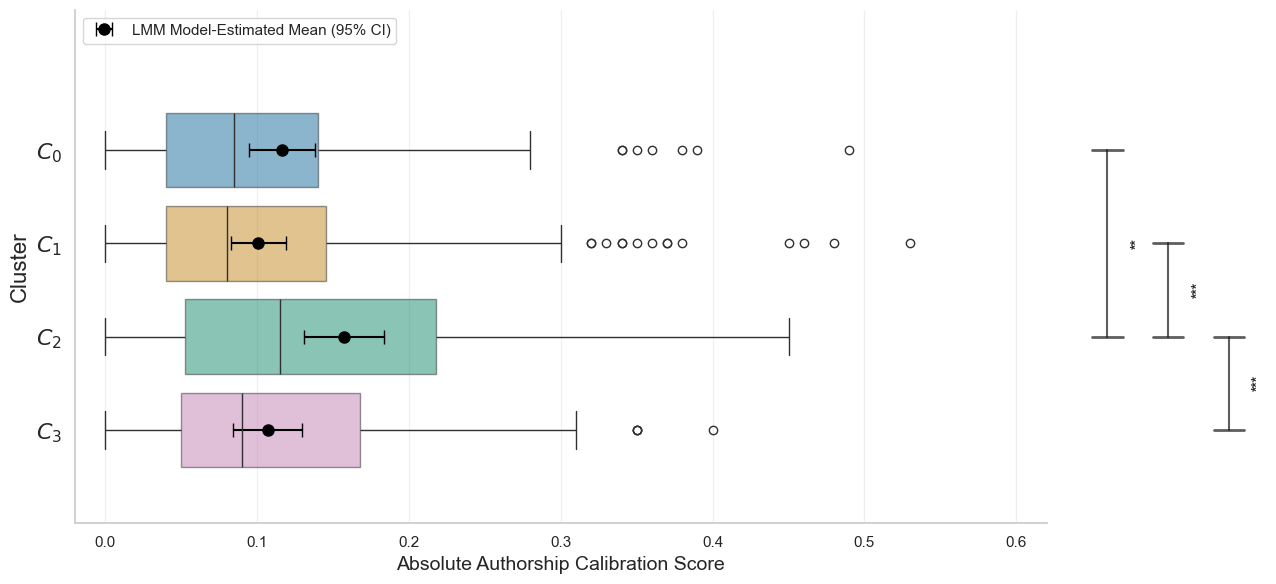

In [22]:
plot_lmm_coeffs(all_metrics, df_emmeans_abs, clusters[::-1], df_posthoc_abs, metric='abs_calibration_score', n_clusters_optimal=4, x_axis_label='Absolute Authorship Calibration Score', name_fig='absolute_calibration', save_fig=True)

## Equality

### LMM model

         Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: equality
No. Observations:  763     Method:             REML    
No. Groups:        53      Scale:              0.0311  
Min. group size:   1       Log-Likelihood:     191.5802
Max. group size:   65      Converged:          Yes     
Mean group size:   14.4                                
-------------------------------------------------------
              Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
C(cluster)[0] 0.353    0.025 14.202 0.000  0.305  0.402
C(cluster)[1] 0.171    0.020  8.439 0.000  0.132  0.211
C(cluster)[2] 0.449    0.030 14.963 0.000  0.390  0.508
C(cluster)[3] 0.318    0.026 12.328 0.000  0.267  0.369
Group Var     0.013    0.020                           



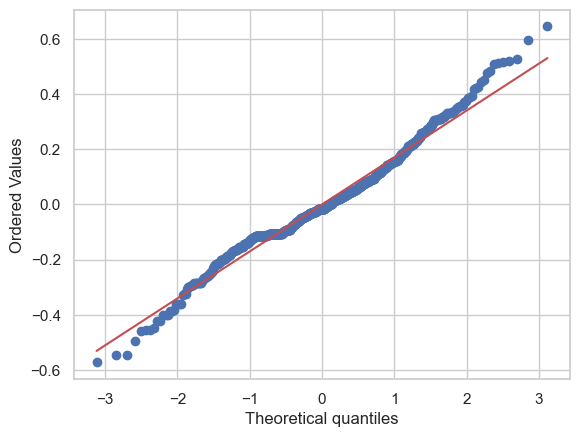

In [23]:
# Ensure cluster is treated as categorical (e.g., C(cluster_id))
all_metrics["cluster"] = all_metrics["cluster"].astype("category")

# 1. Fit the Linear Mixed Model
# 'abs_calibration_score ~ C(cluster_id)' automatically creates dummy variables
lmm_cluster_equality = smf.mixedlm(
    "equality ~ C(cluster) - 1",
    data=all_metrics,
    groups=all_metrics["worker_id"],
)
lmm_cluster_equality_result = lmm_cluster_equality.fit()
print(lmm_cluster_equality_result.summary())

residuals = lmm_cluster_equality_result.resid
probplot(residuals, dist="norm", plot=plt)
plt.title("")
plt.show()

In [24]:
# Extract model-based means and 95% confidence intervals for each cluster
fixed_effects_equality = lmm_cluster_equality_result.fe_params
cov_matrix_equality = lmm_cluster_equality_result.cov_params().loc[fixed_effects_equality.index, fixed_effects_equality.index]

clusters = sorted(all_metrics["cluster"].unique())
means_equality = []
ci_lower_equality = []
ci_upper_equality = []

for cluster in clusters:
    param_name = f"C(cluster)[{cluster}]"
    mean = float(fixed_effects_equality[param_name])
    standard_error = float(np.sqrt(cov_matrix_equality.loc[param_name, param_name]))
    means_equality.append(mean)
    ci_lower_equality.append(mean - 1.96 * standard_error)
    ci_upper_equality.append(mean + 1.96 * standard_error)

df_emmeans_equality = pd.DataFrame(
    {
        "cluster_id": clusters,
        "mean": means_equality,
        "ci_lower": ci_lower_equality,
        "ci_upper": ci_upper_equality,
    }
)

df_emmeans_equality

,cluster_id,mean,ci_lower,ci_upper
0,0,0.353377,0.304608,0.402147
1,1,0.171415,0.131606,0.211225
2,2,0.448830,0.390038,0.507623
3,3,0.318049,0.267482,0.368615


### Wald $\chi^2$ test

In [25]:
hypothesis = hypothesis = (
    "C(cluster)[0] = C(cluster)[1], "
    "C(cluster)[0] = C(cluster)[2], " 
    "C(cluster)[0] = C(cluster)[3] "
)


wald_test = lmm_cluster_equality_result.wald_test(hypothesis)
print(f"Chi2: {wald_test.statistic}")
print(f"p-value: {wald_test.pvalue}")

Chi2: [[131.87536127]]
p-value: 2.132591131633468e-28


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


### T-test for pairwise comparison (with Bonferroni correction)

In [26]:
# 1. Get the fixed-effects parameter names
fe_params_equality = list(lmm_cluster_equality_result.fe_params.index)
n_params = len(fe_params_equality)

# 2. Iterate over all pairs of clusters
pairwise_results = []

for p1, p2 in combinations(fe_params_equality, 2):
    r_matrix = np.zeros(n_params)
    r_matrix[fe_params_equality.index(p1)] = 1
    r_matrix[fe_params_equality.index(p2)] = -1
    r_matrix = r_matrix.reshape(1, -1)  # Reshape to 2D for the t_test function

    # Run the t-test with the NumPy matrix
    test = lmm_cluster_equality_result.t_test(r_matrix)

    # Safely extract the values
    diff = float(np.asarray(test.effect).squeeze())
    sd = float(np.asarray(test.sd).squeeze())
    z_stat = float(np.asarray(test.tvalue).squeeze())
    p_val = float(np.asarray(test.pvalue).squeeze())

    # Clean up names for readability in the table
    label1 = p1.replace("C(cluster)[", "").replace("]", "").replace("[", "")
    label2 = p2.replace("C(cluster)[", "").replace("]", "").replace("[", "")

    pairwise_results.append(
        {
            "Comparison": f"{label1} vs {label2}",
            "Diff (p1 - p2)": diff,
            "Std_Err": sd,
            "z": z_stat,
            "p_value_raw": p_val,
        }
    )

df_posthoc_equality = pd.DataFrame(pairwise_results)

# 3. Bonferroni correction for multiple comparisons
reject, p_adjusted, _, _ = multipletests(
    df_posthoc_equality["p_value_raw"], alpha=0.05, method="bonferroni"
)

# 4. Add the adjusted columns to the DataFrame
df_posthoc_equality["p_value_bonferroni"] = p_adjusted
df_posthoc_equality["Significant (alpha=0.05)"] = reject

# Display the results
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
print(df_posthoc_equality)

  Comparison  Diff (p1 - p2)   Std_Err          z   p_value_raw  p_value_bonferroni  Significant (alpha=0.05)
0     0 vs 1        0.181962  0.021069   8.636283  5.807175e-18        3.484305e-17                      True
1     0 vs 2       -0.095453  0.026106  -3.656351  2.558307e-04        1.534984e-03                      True
2     0 vs 3        0.035329  0.024623   1.434800  1.513442e-01        9.080651e-01                     False
3     1 vs 2       -0.277415  0.027158 -10.214841  1.701575e-24        1.020945e-23                      True
4     1 vs 3       -0.146633  0.022083  -6.639963  3.137617e-11        1.882570e-10                      True
5     2 vs 3        0.130782  0.028897   4.525744  6.018328e-06        3.610997e-05                      True


/Users/treuilli/Documents/GitHub/GenAI_Interaction_Dynamics_Authorship/notebooks/../src/visualization.py:115: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


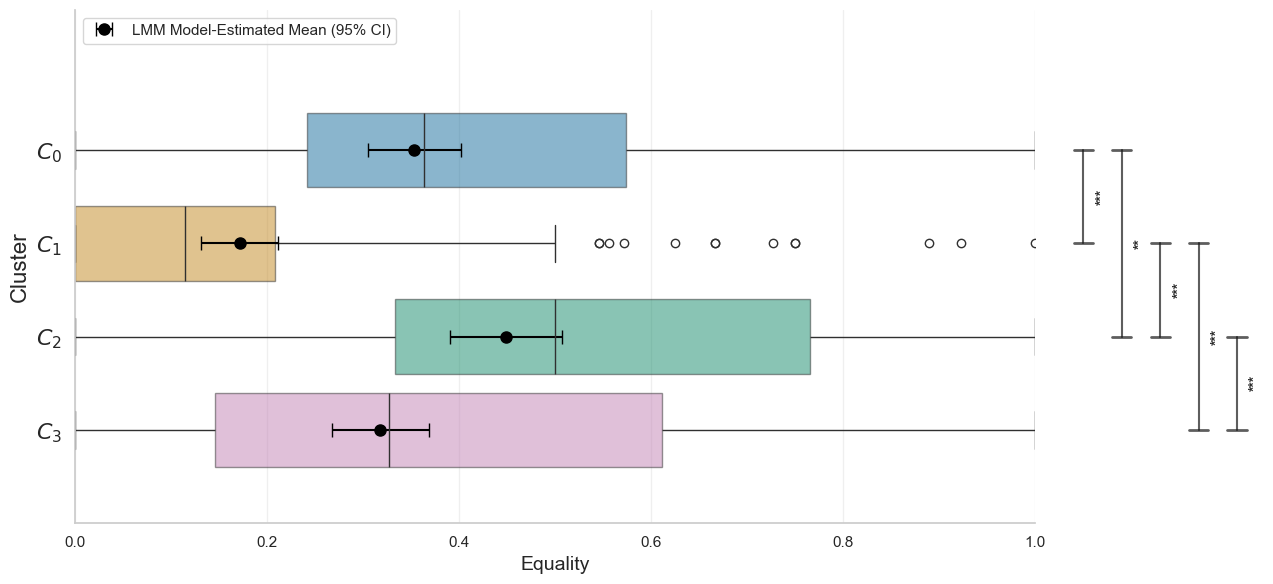

In [27]:
plot_lmm_coeffs(all_metrics, df_emmeans_equality, clusters[::-1], df_posthoc_equality, metric='equality', n_clusters_optimal=4, x_axis_label='Equality', name_fig='equality', save_fig=True)

## Mutuality

### LMM model

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: mutuality
No. Observations: 763     Method:             REML     
No. Groups:       53      Scale:              0.0154   
Min. group size:  1       Log-Likelihood:     450.2229 
Max. group size:  65      Converged:          Yes      
Mean group size:  14.4                                 
-------------------------------------------------------
              Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
C(cluster)[0] 0.266    0.020 13.452 0.000  0.227  0.305
C(cluster)[1] 0.181    0.017 10.678 0.000  0.148  0.215
C(cluster)[2] 0.311    0.023 13.448 0.000  0.266  0.357
C(cluster)[3] 0.222    0.020 10.889 0.000  0.182  0.262
Group Var     0.011    0.021                           



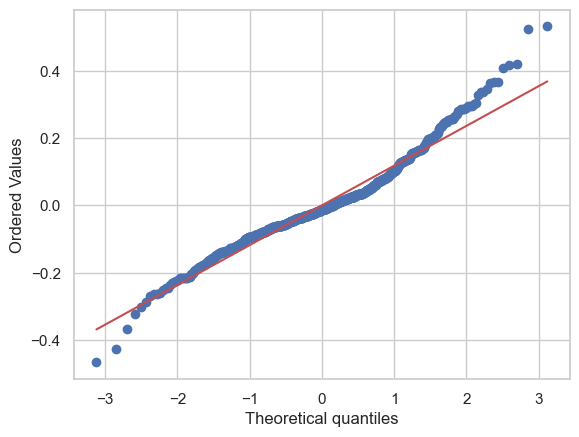

In [28]:
# Ensure cluster is treated as categorical (e.g., C(cluster_id))
all_metrics["cluster"] = all_metrics["cluster"].astype("category")

# 1. Fit the Linear Mixed Model
# 'abs_calibration_score ~ C(cluster_id)' automatically creates dummy variables
lmm_cluster_mutuality = smf.mixedlm(
    "mutuality ~ C(cluster) - 1",
    data=all_metrics,
    groups=all_metrics["worker_id"],
)
lmm_cluster_mutuality_result = lmm_cluster_mutuality.fit()
print(lmm_cluster_mutuality_result.summary())

residuals = lmm_cluster_mutuality_result.resid
probplot(residuals, dist="norm", plot=plt)
plt.title("")
plt.show()

In [29]:
# Extract model-based means and 95% confidence intervals for each cluster
fixed_effects_mutuality = lmm_cluster_mutuality_result.fe_params
cov_matrix_mutuality = lmm_cluster_mutuality_result.cov_params().loc[fixed_effects_mutuality.index, fixed_effects_mutuality.index]

clusters = sorted(all_metrics["cluster"].unique())
means_mutuality = []
ci_lower_mutuality = []
ci_upper_mutuality = []

for cluster in clusters:
    param_name = f"C(cluster)[{cluster}]"
    mean = float(fixed_effects_mutuality[param_name])
    standard_error = float(np.sqrt(cov_matrix_mutuality.loc[param_name, param_name]))
    means_mutuality.append(mean)
    ci_lower_mutuality.append(mean - 1.96 * standard_error)
    ci_upper_mutuality.append(mean + 1.96 * standard_error)

df_emmeans_mutuality = pd.DataFrame(
    {
        "cluster_id": clusters,
        "mean": means_mutuality,
        "ci_lower": ci_lower_mutuality,
        "ci_upper": ci_upper_mutuality,
    }
)

df_emmeans_mutuality

,cluster_id,mean,ci_lower,ci_upper
0,0,0.265822,0.227090,0.304554
1,1,0.181348,0.148061,0.214635
2,2,0.311194,0.265838,0.356551
3,3,0.221945,0.181994,0.261896


### Wald $\chi^2$ test

In [30]:
hypothesis = hypothesis = (
    "C(cluster)[0] = C(cluster)[1], "
    "C(cluster)[0] = C(cluster)[2], " 
    "C(cluster)[0] = C(cluster)[3] "
)


wald_test = lmm_cluster_mutuality_result.wald_test(hypothesis)
print(f"Chi2: {wald_test.statistic}")
print(f"p-value: {wald_test.pvalue}")

Chi2: [[54.8508697]]
p-value: 7.388028489776205e-12


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


### T-test for pairwise comparison (with Bonferroni correction)

In [31]:
# 1. Get the fixed-effects parameter names
fe_params_mutuality = list(lmm_cluster_mutuality_result.fe_params.index)
n_params = len(fe_params_mutuality)

# 2. Iterate over all pairs of clusters
pairwise_results = []

for p1, p2 in combinations(fe_params_mutuality, 2):
    r_matrix = np.zeros(n_params)
    r_matrix[fe_params_mutuality.index(p1)] = 1
    r_matrix[fe_params_mutuality.index(p2)] = -1
    r_matrix = r_matrix.reshape(1, -1)  # Reshape to 2D for the t_test function

    # Run the t-test with the NumPy matrix
    test = lmm_cluster_mutuality_result.t_test(r_matrix)

    # Safely extract the values
    diff = float(np.asarray(test.effect).squeeze())
    sd = float(np.asarray(test.sd).squeeze())
    z_stat = float(np.asarray(test.tvalue).squeeze())
    p_val = float(np.asarray(test.pvalue).squeeze())

    # Clean up names for readability in the table
    label1 = p1.replace("C(cluster)[", "").replace("]", "").replace("[", "")
    label2 = p2.replace("C(cluster)[", "").replace("]", "").replace("[", "")

    pairwise_results.append(
        {
            "Comparison": f"{label1} vs {label2}",
            "Diff (p1 - p2)": diff,
            "Std_Err": sd,
            "z": z_stat,
            "p_value_raw": p_val,
        }
    )

df_posthoc_mutuality = pd.DataFrame(pairwise_results)

# 3. Bonferroni correction for multiple comparisons
reject, p_adjusted, _, _ = multipletests(
    df_posthoc_mutuality["p_value_raw"], alpha=0.05, method="bonferroni"
)

# 4. Add the adjusted columns to the DataFrame
df_posthoc_mutuality["p_value_bonferroni"] = p_adjusted
df_posthoc_mutuality["Significant (alpha=0.05)"] = reject

# Display the results
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
print(df_posthoc_mutuality)

  Comparison  Diff (p1 - p2)   Std_Err         z   p_value_raw  p_value_bonferroni  Significant (alpha=0.05)
0     0 vs 1        0.084474  0.014846  5.690183  1.269035e-08        7.614208e-08                      True
1     0 vs 2       -0.045372  0.018440 -2.460547  1.387252e-02        8.323515e-02                     False
2     0 vs 3        0.043877  0.017379  2.524754  1.157793e-02        6.946757e-02                     False
3     1 vs 2       -0.129846  0.019250 -6.745340  1.526693e-11        9.160158e-11                      True
4     1 vs 3       -0.040597  0.015634 -2.596611  9.414850e-03        5.648910e-02                     False
5     2 vs 3        0.089250  0.020405  4.373947  1.220200e-05        7.321201e-05                      True


/Users/treuilli/Documents/GitHub/GenAI_Interaction_Dynamics_Authorship/notebooks/../src/visualization.py:115: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


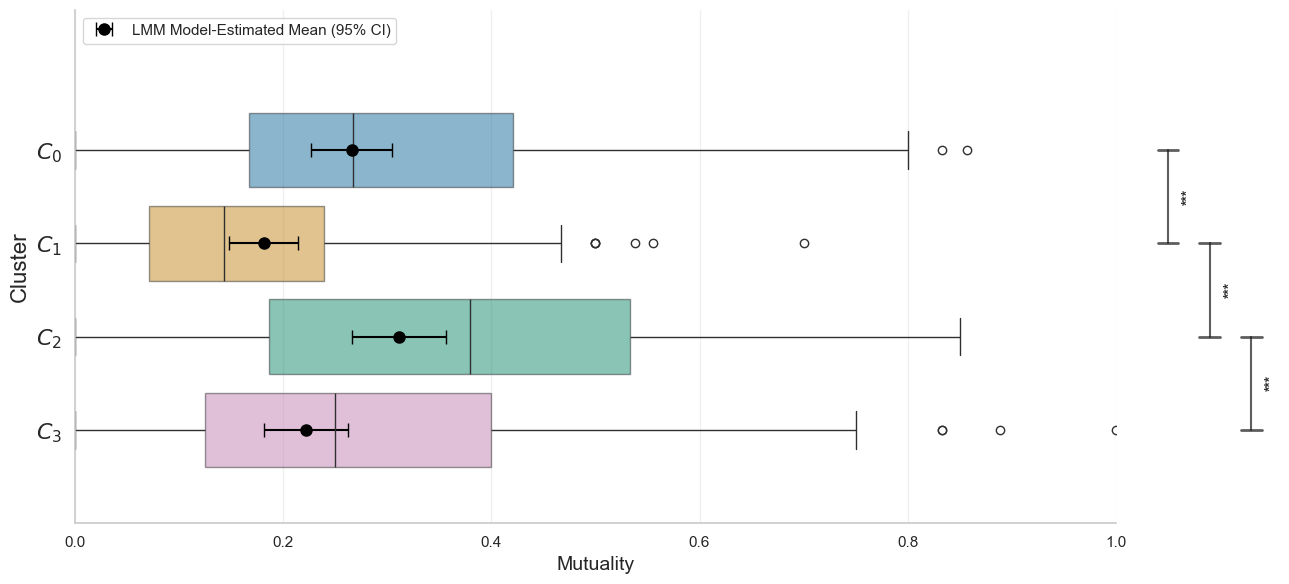

In [32]:
plot_lmm_coeffs(all_metrics, df_emmeans_mutuality, clusters[::-1], df_posthoc_mutuality, metric='mutuality', n_clusters_optimal=4, x_axis_label='Mutuality', name_fig='mutuality', save_fig=True)

# Framework of dyadic pairwork [Storch, 2002]

In [33]:
palette = sns.color_palette("colorblind")
my_palette = [palette[0], palette[1], palette[2], palette[4]]

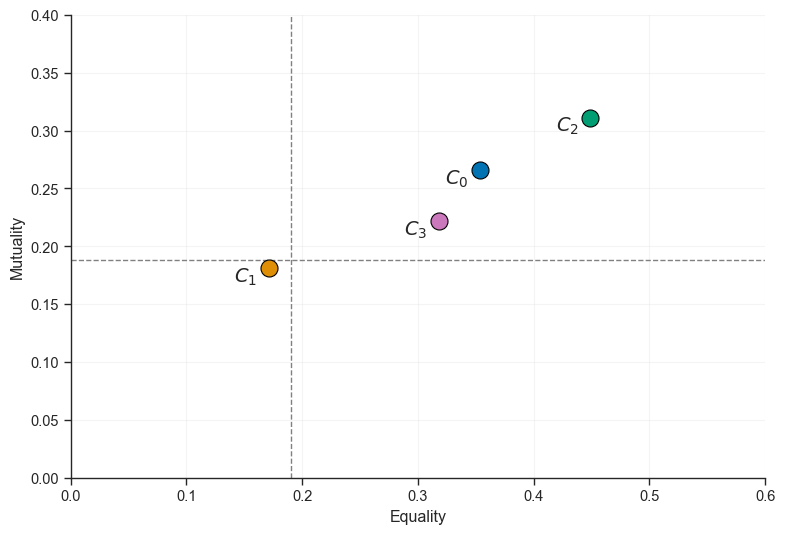

<Figure size 640x480 with 0 Axes>

In [36]:
cluster_means = (
    df_emmeans_equality[["cluster_id", "mean"]]
    .rename(columns={"mean": "equality"})
    .merge(
        df_emmeans_mutuality[["cluster_id", "mean"]]
        .rename(columns={"mean": "mutuality"}),
        on="cluster_id",
        validate="one_to_one",
    )
)

fig, ax = plt.subplots(figsize=(8, 8))

for _, row in cluster_means.iterrows():
    cluster_id = int(row["cluster_id"])
    equality_mean = row["equality"]
    mutuality_mean = row["mutuality"]

    ax.scatter(
        equality_mean,
        mutuality_mean,
        color=my_palette[cluster_id],
        marker="o",
        s=150,
        edgecolor="black",
        zorder=3,
    )
    ax.annotate(
        f"$C_{{{cluster_id}}}$",
        (equality_mean, mutuality_mean),
        xytext=(-25, -10),
        textcoords="offset points",
        fontsize=14,
    )

# Midpoint lines divide the chart into low/high regions.
ax.axvline(0.190, color="gray", linestyle="--", linewidth=1)
ax.axhline(0.188, color="gray", linestyle="--", linewidth=1)

ax.set(
    xlim=(0, 0.6),
    ylim=(0, 0.4),
    xlabel="Equality",
    ylabel="Mutuality",
    # title="Mean equality and mutuality by cluster",
)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

cluster_means.round(3)

plt.savefig('../figures/equality_mutuality_clusters.png')


# Correlation analysis

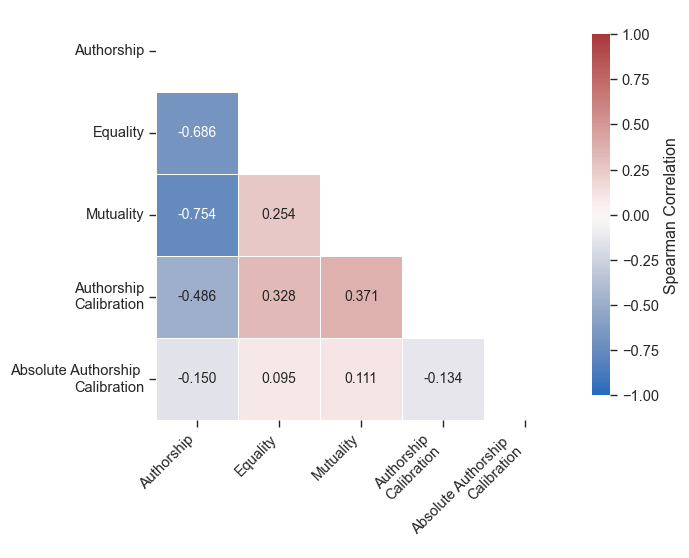

In [37]:
# Set publication-quality aesthetics
sns.set_theme(style="ticks", context="paper", font_scale=1.2)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['pdf.fonttype'] = 42 # For editable text in Illustrator/PDFs

fig_d, ax_d = plt.subplots(figsize=(7, 6))

# Select only numerical features for correlation
cols_for_corr = ['written_by_human', 'equality', 'mutuality', 'calibration_score', 'abs_calibration_score']
corr_matrix = all_metrics[cols_for_corr].corr(method='spearman') # Using Spearman for non-parametric behavioral data

# Generate a custom diverging colormap and a triangular mask
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(240, 20, as_cmap=True)

sns.heatmap(
    corr_matrix, mask=mask, cmap='vlag', vmax=1, vmin=-1, center=0,
    square=True, linewidths=.5, cbar_kws={"shrink": .8, "label": "Spearman Correlation"},
    annot=True, fmt=".3f", annot_kws={"size": 10}, ax=ax_d
)

# Clean up labels for presentation
ax_d.set_xticklabels(['Authorship', 'Equality', 'Mutuality', 'Authorship\nCalibration', 'Absolute Authorship \nCalibration'], rotation=45, ha='right')
ax_d.set_yticklabels(['Authorship', 'Equality', 'Mutuality', 'Authorship\nCalibration', 'Absolute Authorship \nCalibration'], rotation=0)

ax_d.tick_params(axis='y', top=False, bottom=True, labeltop=False, labelbottom=True)
ax_d.tick_params(axis='x', left=True, right=False, labelleft=True, labelright=False)
ax_d.tick_params(top=False, right=False) 

plt.tight_layout()
plt.savefig('../figures/heatmap.png')
plt.show()
